<a href="https://colab.research.google.com/github/uranovnass/Machine-Learning/blob/main/ml7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('/content/housing.csv')

print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

Размер датасета: (20640, 10)

Первые 5 строк:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Типы данных:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

Пропущенные значения:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [2]:
# Удаляем строки, в которых отсутствует целевая переменная
df = df.dropna(subset=['median_house_value']).copy()

X = df.drop(columns=['median_house_value'])
y = df['median_house_value']

# Числовые и категориальные признаки
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Заполняем пропуски в числовых столбцах медианой
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Заполняем пропуски и кодируем категории
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)
print("Числовых признаков:", len(num_cols))
print("Категориальных признаков:", len(cat_cols))

Обучающая выборка: (16512, 9)
Тестовая выборка: (4128, 9)
Числовых признаков: 8
Категориальных признаков: 1


In [3]:
def evaluate_model(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    return {
        'Модель': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions)
    }


tree = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

forest_default = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

results = []

results.append(evaluate_model(
    'Decision Tree',
    tree, X_train, X_test, y_train, y_test
))

results.append(evaluate_model(
    'Random Forest default',
    forest_default, X_train, X_test, y_train, y_test
))

comparison = pd.DataFrame(results)
display(comparison.round(3))

,Модель,MAE,RMSE,R2
0,Decision Tree,43631.171,69136.031,0.635
1,Random Forest default,31636.350,48977.064,0.817


In [5]:
forest_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [None, 20],
    'model__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:")
print(grid_search.best_params_)

print("\nЛучший RMSE на кросс-валидации:")
print(round(-grid_search.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Лучшие параметры:
{'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}

Лучший RMSE на кросс-валидации:
50026.732


In [6]:
best_forest = grid_search.best_estimator_

tuned_result = evaluate_model(
    'Random Forest tuned',
    best_forest,
    X_train, X_test, y_train, y_test
)

results.append(tuned_result)

comparison = pd.DataFrame(results)
display(comparison.round(3))

,Модель,MAE,RMSE,R2
0,Decision Tree,43631.171,69136.031,0.635
1,Random Forest default,31636.350,48977.064,0.817
2,Random Forest tuned,31610.900,49013.663,0.817


,Признак,Важность
7,num__median_income,0.499578
9,cat__ocean_proximity_INLAND,0.144573
0,num__longitude,0.105840
1,num__latitude,0.101200
2,num__housing_median_age,0.050499
5,num__population,0.029928
4,num__total_bedrooms,0.021184
3,num__total_rooms,0.020954
6,num__households,0.016045
12,cat__ocean_proximity_NEAR OCEAN,0.005853


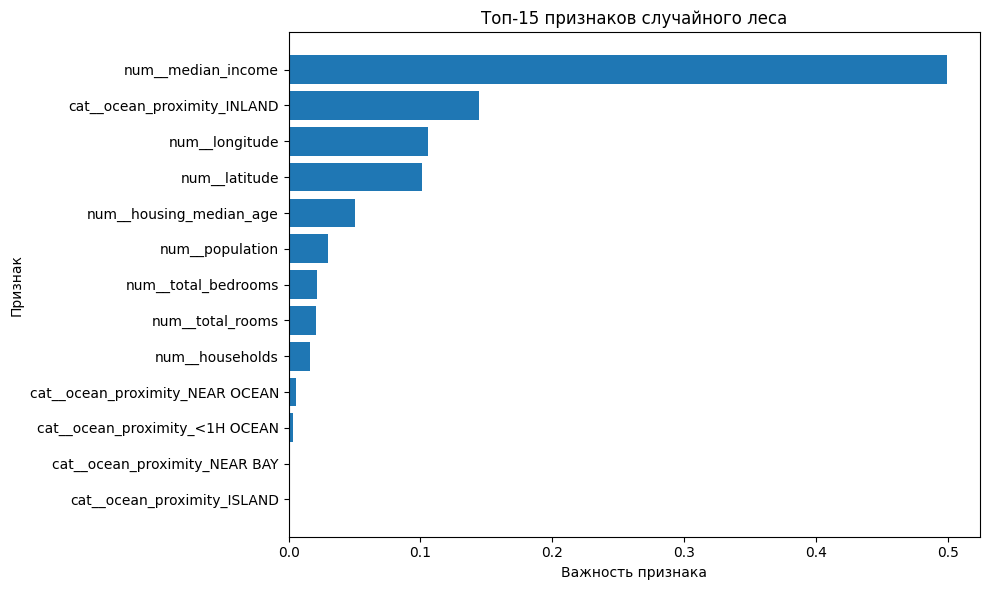

In [7]:
fitted_preprocessor = best_forest.named_steps['preprocessor']
fitted_model = best_forest.named_steps['model']

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_model.feature_importances_

importance_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность': importances
}).sort_values('Важность', ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

top_features = importance_df.head(15).sort_values('Важность')

plt.barh(top_features['Признак'], top_features['Важность'])
plt.xlabel('Важность признака')
plt.ylabel('Признак')
plt.title('Топ-15 признаков случайного леса')
plt.tight_layout()
plt.show()

In [8]:
# Сортируем важности и находим признаки,
# которые соответствуют исходным столбцам
raw_importance = {}

for col in X_train.columns:
    prefix_num = f'num__{col}'
    prefix_cat = f'cat__{col}_'

    mask = (
        importance_df['Признак'].str.startswith(prefix_num)
        | importance_df['Признак'].str.startswith(prefix_cat)
    )

    raw_importance[col] = importance_df.loc[mask, 'Важность'].sum()

raw_importance = pd.Series(raw_importance).sort_values(ascending=False)

n_keep = max(1, int(np.ceil(len(raw_importance) * 0.8)))
selected_features = raw_importance.head(n_keep).index.tolist()

print("Исходное количество признаков:", X_train.shape[1])
print("Оставляем признаков:", len(selected_features))
print("\nИсключённые признаки:")
print(raw_importance.drop(selected_features).index.tolist())

Исходное количество признаков: 9
Оставляем признаков: 8

Исключённые признаки:
['households']


In [11]:
X_train_reduced = X_train[selected_features]
X_test_reduced = X_test[selected_features]

reduced_preprocessor = ColumnTransformer([
    ('num', num_pipe, [
        c for c in selected_features if c in num_cols
    ]),
    ('cat', cat_pipe, [
        c for c in selected_features if c in cat_cols
    ])
])

# Берём лучшие параметры из GridSearchCV
rf_params = {
    key.replace('model__', ''): value
    for key, value in grid_search.best_params_.items()
}

reduced_forest = Pipeline([
    ('preprocessor', reduced_preprocessor),
    ('model', RandomForestRegressor(
        **rf_params,
        random_state=42,
        n_jobs=-1
    ))
])

print("Параметры модели:", rf_params)

Параметры модели: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}


In [12]:
reduced_result = evaluate_model(
    'Random Forest reduced',
    reduced_forest,
    X_train_reduced,
    X_test_reduced,
    y_train,
    y_test
)

results.append(reduced_result)

comparison = pd.DataFrame(results)
display(comparison.round(3))

,Модель,MAE,RMSE,R2
0,Decision Tree,43631.171,69136.031,0.635
1,Random Forest default,31636.350,48977.064,0.817
2,Random Forest tuned,31610.900,49013.663,0.817
3,Random Forest reduced,31501.804,49019.568,0.817


In [13]:
best_params_clean = {
    key.replace('model__', ''): value
    for key, value in grid_search.best_params_.items()
}

reduced_forest = Pipeline([
    ('preprocessor', reduced_preprocessor),
    ('model', RandomForestRegressor(
        **best_params_clean,
        random_state=42,
        n_jobs=-1
    ))
])

reduced_result = evaluate_model(
    'Random Forest reduced',
    reduced_forest,
    X_train_reduced,
    X_test_reduced,
    y_train,
    y_test
)

results.append(reduced_result)

comparison = pd.DataFrame(results)
display(comparison.round(3))

,Модель,MAE,RMSE,R2
0,Decision Tree,43631.171,69136.031,0.635
1,Random Forest default,31636.350,48977.064,0.817
2,Random Forest tuned,31610.900,49013.663,0.817
3,Random Forest reduced,31501.804,49019.568,0.817
4,Random Forest reduced,31501.804,49019.568,0.817


In [14]:
comparison = pd.DataFrame(results)
display(comparison.round(3))

,Модель,MAE,RMSE,R2
0,Decision Tree,43631.171,69136.031,0.635
1,Random Forest default,31636.350,48977.064,0.817
2,Random Forest tuned,31610.900,49013.663,0.817
3,Random Forest reduced,31501.804,49019.568,0.817
4,Random Forest reduced,31501.804,49019.568,0.817


## Выводы

В ходе практической работы был изучен алгоритм случайного леса (Random Forest) для решения задачи регрессии.

1. Были обучены и сравнены дерево решений, случайный лес с параметрами по умолчанию и случайный лес с подобранными гиперпараметрами.
2. Для подбора параметров `n_estimators`, `max_depth` и `min_samples_leaf` использовался `GridSearchCV` с кросс-валидацией.
3. Качество моделей оценивалось с помощью MAE, RMSE и коэффициента детерминации R².
4. Был построен график важности признаков и проведён эксперимент с исключением наименее важных признаков.
5. После сравнения результатов установлено, что лучшей оказалась модель **[название модели по результатам таблицы]**. Её RMSE составил **[значение]**, а R² — **[значение]**.
6. Эксперимент с сокращением признаков показал, что удаление менее важных признаков **[улучшило / ухудшило / практически не изменило]** качество модели.

Таким образом, случайный лес позволяет сравнить влияние разных гиперпараметров и важность признаков на качество прогнозирования.